### Alzheimer's Progression Prediction model 
##### via MRI image dataset from OASIS Alzheimer's dataset
---
Rudy Gamboa | Alex Hernandez | Jeff Ock

In [1]:
## Import modules
# for Data
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# for Model
import tensorflow as tf
from tensorflow import keras
import tensorflow.keras                             # type: ignore
from tensorflow.keras.layers import Dense,Dropout   # type: ignore
from tensorflow.keras.applications import MobileNet # type: ignore
from tensorflow.keras.models import Model           # type: ignore
from tensorflow.keras.optimizers import Adam        # type: ignore
# for Other
import os

---
##### Get Data:
---

In [9]:
# Specify the path to the main data folder
cwd = os.getcwd()
train_path = os.path.join(cwd, "Reduced-Alzheimers-ADNI", "train")

# Create train_generator iterator object
train_datagen=ImageDataGenerator(preprocessing_function=preprocess_input,
                                 shear_range = 0.15,
                                 zoom_range =.15,
                                 rotation_range =5,
                                 fill_mode='nearest')

train_generator=train_datagen.flow_from_directory(train_path, 
                                                 target_size=(256,256),
                                                 color_mode='rgb',
                                                 batch_size= 16,
                                                 seed=1,
                                                 class_mode='categorical',
                                                 shuffle=True)   # set to False to show images in the same order for display


Found 672 images belonging to 5 classes.


---
##### Data Exploration:
---

In [15]:
# Basic info
train_generator.__dict__.keys()

dict_keys(['image_data_generator', 'target_size', 'keep_aspect_ratio', 'color_mode', 'data_format', 'image_shape', 'save_to_dir', 'save_prefix', 'save_format', 'interpolation', 'split', 'subset', 'directory', 'classes', 'class_mode', 'dtype', 'samples', 'num_classes', 'class_indices', 'filenames', '_filepaths', 'n', 'batch_size', 'seed', 'shuffle', 'batch_index', 'total_batches_seen', 'lock', 'index_array', 'index_generator', '_workers', '_use_multiprocessing', '_max_queue_size'])

In [16]:
train_generator.class_indices

{'Reduced AD': 0,
 'Reduced CN': 1,
 'Reduced EMCI': 2,
 'Reduced LMCI': 3,
 'Reduced MCI': 4}

In [17]:
train_generator.n

672

In [ ]:
# Baseline Accuracy
baseline_acc = 150/672
print(baseline_acc)

0.22321428571428573


Image example: Reduced LMCI


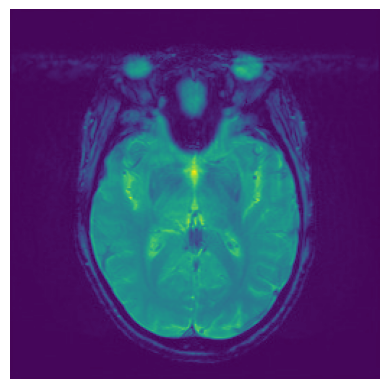

Image dimensions: (256, 256)
Number of channels: 3


In [26]:
# Get random image from Reduced AD
labels = os.listdir(train_path)
random_label = np.random.choice(labels)
random_img = np.random.choice((os.listdir(os.path.join(train_path, random_label))))
img_path = os.path.join(train_path, random_label, random_img)
img = plt.imread(img_path)

# Display the above image
print("Image example:", random_label)
plt.imshow(img)
plt.axis('off')
plt.show()

# Image info
print("Image dimensions:", img.shape[0:2])
print("Number of channels:", "3")

In [27]:
# Number of samples
print("Number of samples by class:")
for label in sorted(labels):
  print(f"- {label}: {len(os.listdir(os.path.join(train_path, label)))}")

Number of samples by class:
- Reduced AD: 150
- Reduced CN: 150
- Reduced EMCI: 150
- Reduced LMCI: 72
- Reduced MCI: 150


---
##### Data Curation:
---

In [ ]:
# code...

---
##### Data Augmentation / Feature Engineering:
---

In [ ]:
# code...

---
##### Final Data Visualization:
---

In [ ]:
# code...

---
##### Define Model:
---

In [12]:
# Base model, TBD
from tensorflow.keras.applications import MobileNet
base_model=MobileNet(weights='imagenet',
                     include_top=False, 
                     input_shape=(256,256,3))  # shape of RGB images

# Modification of Base model
from tensorflow.keras import models
from tensorflow.keras import layers
# Define the L2 regularizer
from tensorflow.keras import regularizers
l2_reg = regularizers.l2(0.0001)  # You can adjust the regularization strength

# Build the model
model = models.Sequential()
model.add(base_model)
model.add(layers.Flatten())

# Add L2 regularization to the Dense layers
model.add(layers.Dense(1024, activation='relu', kernel_regularizer=l2_reg))
model.add(Dropout(0.5))
model.add(layers.Dense(1024, activation='relu', kernel_regularizer=l2_reg))
model.add(Dropout(0.5))
model.add(layers.Dense(512, activation='relu', kernel_regularizer=l2_reg))
model.add(layers.Dense(5, activation='softmax'))  # Output layer (no regularization here)

C:\Users\jeffo_work\AppData\Local\Temp\ipykernel_33412\3373247965.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model=MobileNet(weights='imagenet',


---
##### Model Training:
---

Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 128s 3s/step - accuracy: 0.2703 - loss: 23.4433
Epoch 2/15


C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2032.0_x64__qbz5n2kfra8p0\Lib\contextlib.py:158: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(value)


43/43 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.4228 - loss: 1.7870
Epoch 3/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 109s 3s/step - accuracy: 0.4212 - loss: 1.7095
Epoch 4/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.4987 - loss: 1.5500
Epoch 5/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 107s 2s/step - accuracy: 0.5486 - loss: 1.5020
Epoch 6/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 110s 3s/step - accuracy: 0.5427 - loss: 1.4835
Epoch 7/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 110s 3s/step - accuracy: 0.5310 - loss: 1.4430
Epoch 8/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 110s 3s/step - accuracy: 0.6305 - loss: 1.3076
Epoch 9/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.5762 - loss: 1.4138
Epoch 10/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.5783 - loss: 1.4076
Epoch 11/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.6130 - loss: 1.4387
Epoch 12/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.5828 - loss: 1.3859
Epoch 13/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.6468 - loss:

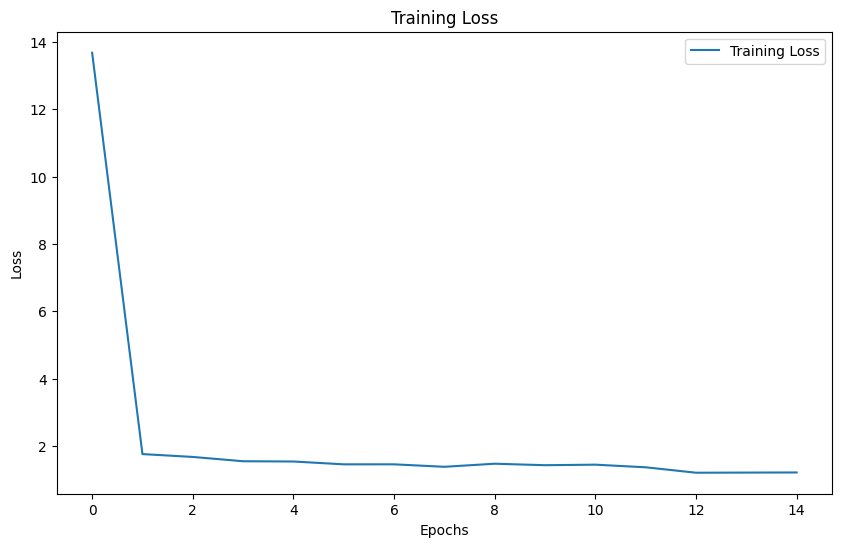

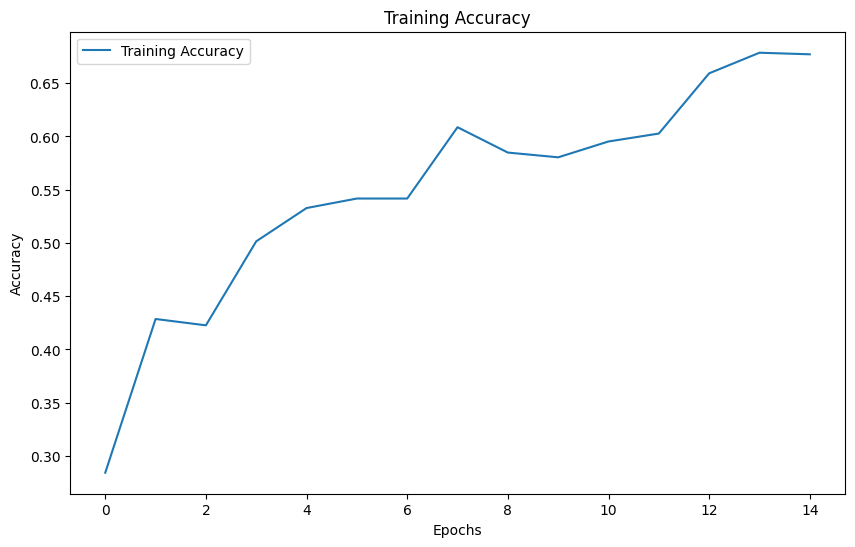

In [13]:
# Compile and run the model
model.compile(optimizer='Adam',loss='categorical_crossentropy',metrics=['accuracy'])

step_size_train=train_generator.n//train_generator.batch_size + 1
history = model.fit(train_generator,
          steps_per_epoch=step_size_train,
          epochs=15)

# Plotting Training Loss
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Plotting Training Accuracy
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

---
##### Model Testing:
---

In [ ]:
# code...

---
##### Final Results:
---

In [ ]:
# code...